# Markov chains: a particle in a potential

A particle hops on a discrete 1D grid inside a harmonic potential, and later with a central potential barrier. This notebook builds the Markov transition matrix, evolves the probability distribution by matrix multiplication and from the eigen-decomposition, checks the eigenvalue and eigenvector properties, recovers the Boltzmann equilibrium distribution, and studies the equilibration time as a function of hop size σ, inverse temperature β and barrier height V₀.

*Problem statements are summarised in English; my answers and code are in Portuguese.*

In [ ]:
import numpy as np
import scipy as sci
import matplotlib.pyplot as plt
import mpmath as mp

## 1. Harmonic potential
### 1.1 Markov transition matrix

Assumindo que a partícula só pode tomar como posição valores discretos de $x \in [0, 1, 2, ..., L]$, é possível construír uma matriz de transição de Markov $W$, sendo que cada par de índices $W_{ij} = P(X_{t+1} = i | X_{t} = j)$ corresponde à probabilidade de a partícula transicionar da posição $j$ para a posição $i$ num intervalo de tempo $\Delta t = 1$.

$$W = \begin{pmatrix}
P(0 \to 0) & P(1 \to 0) & \cdots & P(L \to 0) \\
P(0 \to 1) & P(1 \to 1) & \cdots & P(L \to 1) \\
\vdots & \vdots & \ddots & \vdots \\
P(0 \to L) & P(1 \to L) & \cdots & P(L \to L)\\
\end{pmatrix}$$

aonde temos obrigatoriamente as condições: 
$$W_{ij} \geq 0, \forall i,j$$
$$\sum_{j}W_{ij} = 1, \forall i$$

Para a implementação do algoritmo de Metropolis, temos para cada transição a probabilidade de essa transição ser proposta e depois a probabilidade de ser aceite uma vez proposta, logo cada elemento da matriz de transição de Markov $W$ será:

$$W_{ij} = A_{ij}E_{ij} = \min\left[1,e^{\beta\left[V_{h}\left(j\right)-V_{h}\left(i\right)\right]}\right]\mathcal{N}_{\sigma}\exp\left[-\frac{\left(i-j\right)^{2}}{2\sigma^{2}L^{2}}\right]$$,

aonde $N_{\sigma}$ é uma constante de normalização de modo a que:
$$\sum_{j}W_{ij} = 1, \forall i$$.

In [ ]:
def Markov(L, sigma, beta):
    W = np.zeros((L+1, L+1))
    for i in range(L+1):
        for j in range(L+1):
            E_ij = np.exp(-(i - j)**2 / (2 * sigma**2 * L**2))
            V_i = 32 * (i/L - 0.5)**2
            V_j = 32 * (j/L - 0.5)**2
            A_ij = min(1, np.exp(beta * (V_j - V_i)))
            W[i,j] = A_ij * E_ij
    W /= W.sum(axis = 0)
    return W

### 1.2 Time evolution by matrix multiplication

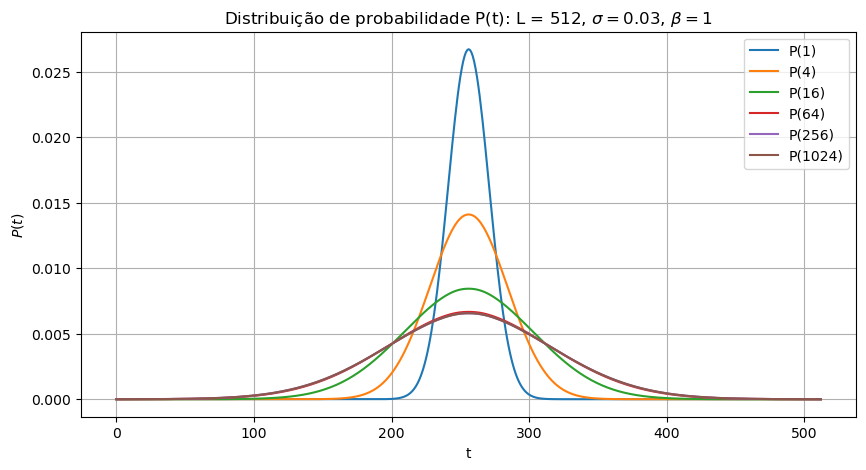

In [ ]:
def Markov_Evolution(L, sigma, beta, t):
    P_0 = np.zeros(L+1)
    P_0[L//2] = 1
    W = Markov(L, sigma, beta)
    W_t = np.linalg.matrix_power(W, t)
    P_f = np.dot(W_t, P_0)
    return P_f

t = np.array([1, 4, 16, 64, 256, 1024])

for T in t:
    plt.figure(figsize = (10,5), num = 1)
    plt.title(r'Distribuição de probabilidade P(t): L = 512, $\sigma = 0.03$, $\beta = 1$')
    plt.xlabel('t')
    plt.ylabel('$P(t)$')
    plt.grid(visible = True)
    plt.plot(np.arange(0,513,1), Markov_Evolution(L = 512, sigma = 0.03, beta = 1, t = T), label = "P({0})" .format(T))
    plt.legend()

### 1.3 Eigen-decomposition (`scipy.linalg.eig`)
#### a) All eigenvalues have modulus ≤ 1

In [ ]:
W = Markov(L = 512, sigma = 0.03, beta = 1)
eigvals = sci.linalg.eig(W)[0]
np.set_printoptions(precision = 2)
print(np.abs(eigvals))

[1.00e+00 9.72e-01 9.50e-01 9.27e-01 9.02e-01 8.71e-01 8.37e-01 7.97e-01
 7.55e-01 7.09e-01 6.63e-01 6.14e-01 5.67e-01 5.19e-01 4.74e-01 4.29e-01
 3.87e-01 3.47e-01 3.10e-01 2.75e-01 2.44e-01 2.15e-01 1.90e-01 1.66e-01
 1.46e-01 1.28e-01 1.12e-01 9.83e-02 8.63e-02 7.58e-02 6.70e-02 5.92e-02
 5.26e-02 4.69e-02 4.21e-02 3.78e-02 3.43e-02 3.11e-02 2.85e-02 2.61e-02
 2.41e-02 2.23e-02 2.07e-02 1.93e-02 1.80e-02 1.69e-02 1.59e-02 1.49e-02
 1.41e-02 1.33e-02 1.27e-02 1.20e-02 1.14e-02 1.09e-02 1.04e-02 9.90e-03
 9.48e-03 9.07e-03 8.70e-03 8.34e-03 8.02e-03 7.70e-03 7.42e-03 7.14e-03
 6.89e-03 6.64e-03 6.42e-03 6.19e-03 6.00e-03 5.79e-03 5.62e-03 5.43e-03
 5.28e-03 5.11e-03 4.97e-03 4.81e-03 4.68e-03 4.54e-03 4.43e-03 4.30e-03
 4.19e-03 4.07e-03 3.98e-03 3.87e-03 3.78e-03 3.68e-03 3.59e-03 3.50e-03
 3.42e-03 3.34e-03 3.27e-03 3.19e-03 3.12e-03 3.04e-03 2.99e-03 2.91e-03
 2.86e-03 2.79e-03 2.74e-03 2.68e-03 2.63e-03 2.57e-03 2.53e-03 2.47e-03
 2.43e-03 2.38e-03 2.34e-03 2.29e-03 2.25e-03 2.21e

#### b) Left and right eigenvectors are biorthonormal

De modo a provar a relação descrita no enunciado, podemos criar duas matrizes com os vetores próprios normalizados. As filas da matriz $L$ são os vetores próprios à esquerda da matriz de Markov $W$ e as colunas da matriz $R$ são os vetores próprios à direita de $W$, tal que:
$$LR = I$$

No cálculo computacional feito de acordo com a normalização acima pedida podem existir alguns valores de ruído, sendo que não é obtida exatamente a matriz identidade $I$. Elevados valores de ruído para $i,j$ elevados pode se dever ao facto de a matriz $W$ de transição decaír exponencialmente com o fator Gaussiano referido acima no enunciado, sendo que os erros de precisão numéricos também se podem acumular para elevados índices $i$ e $j$ quando temos em conta a condição de ortogonalidade.

In [ ]:
def Diag(L, sigma, beta):
    W = Markov(L, sigma, beta)

    # O SciPy oferce vetores com norma = 1
    eigvals, R_V = sci.linalg.eig(W)
    L_V = sci.linalg.eig(W.T)[1]

    # Matrizes
    R_M = np.zeros((513, 513))
    L_M = np.zeros((513, 513))

    for k in range(W.shape[1]):
        if np.isclose(eigvals[k], 1):
            R_M[:,k] = R_V[:,k] / np.sum(R_V[:,k])
            L_M[:,k] = L_V[:,k] / np.sum(L_V[:,k] * R_M[:,k])
        else:
            L_M[:,k] = L_V[:,k] / np.linalg.norm(L_V[:,k])
            R_M[:,k] = R_V[:,k] / np.sum(R_V[:,k] * L_M[:,k])
    return R_M, L_M

R_M, L_M = Diag(L = 512, sigma = 0.03, beta = 1)
np.set_printoptions(precision = 2)
print(np.dot(L_M.T, R_M))

[[ 1.00e+00  7.94e-14 -1.41e-12 ...  2.24e+00 -1.83e-03 -7.37e-02]
 [-3.31e-15  1.00e+00 -3.74e-13 ... -1.48e-02 -5.65e-05 -1.49e-03]
 [ 2.18e-16 -5.14e-14  1.00e+00 ...  1.33e-02 -1.89e-05 -1.40e-03]
 ...
 [-1.46e-18  1.27e-16  9.45e-17 ...  9.89e-01  5.59e-01 -1.95e+01]
 [-1.21e-18  1.20e-16  2.16e-16 ...  7.23e+01  1.00e+00  2.04e+01]
 [-1.08e-18 -2.50e-16  1.46e-16 ...  1.41e+03  1.49e-01  1.00e+00]]


#### c) The equilibrium distribution is the Boltzmann distribution

No equilíbrio, a distribuição de probabilidades vai ser invariante perante uma multiplicação da matriz de transição de Markov $W$, ou seja, é atingo o regime assimptótico:
$$P_i = \sum_{j} W_{ij} P_j$$
Logo a distribuição de probabilidades de equilíbrio é o vetor próprio à direita da matriz de Markov $W$ com $\lambda = 1$.

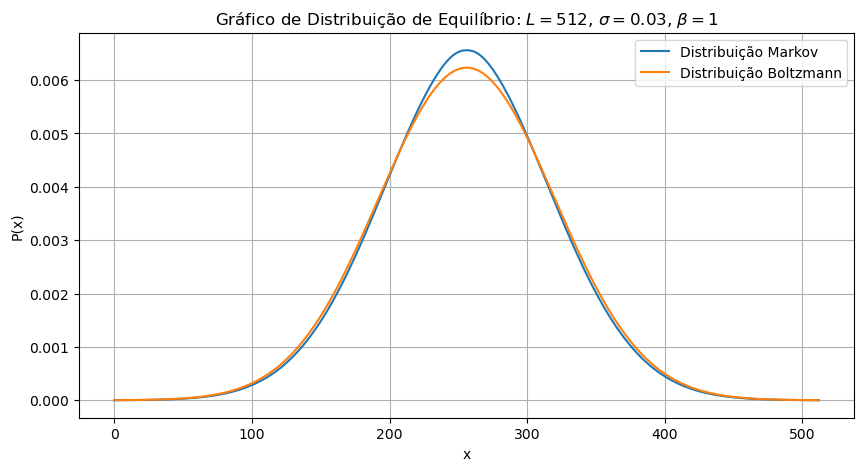

In [ ]:
def P_Boltzmann(L, beta):
    x = np.arange(0, L+1, 1)
    V = 32 * (x/L - 0.5)**2
    P = np.exp(-beta * V)
    return P / np.sum(P)

Pf_Normed = R_M[:,0] / np.sum(R_M[:,0])
P_Boltz = P_Boltzmann(512, beta = 1)
x = np.arange(0, 513, 1)

plt.figure(figsize = (10,5))
plt.xlabel("x")
plt.ylabel("P(x)")
plt.title(r"Gráfico de Distribuição de Equilíbrio: $L = 512$, $\sigma = 0.03$, $\beta = 1$")
plt.grid(visible = True)
plt.plot(x, Pf_Normed, label = "Distribuição Markov")
plt.plot(x, P_Boltz, label = "Distribuição Boltzmann")
plt.legend()
plt.show()

### 1.4 Time evolution from the eigenbasis

Os vetores próprios de $W$ tendo todos valores próprios $\lambda$ diferentes formam uma base completa no espaço vetorial de probabilidades associado à matriz de Markov $W$. Podemos então escrever:
$$P\left(0\right) = \sum_{\alpha} a_{\alpha} r^{(\alpha)}$$

Para obter os coeficientes $a_{\alpha}$, projeta-se $P(0)$ no vetor próprio esquerdo $l^{(\beta)}$:
$$l^{\beta}P(0) = \sum_{\alpha} a_{\alpha} l^{\beta} r^{\alpha} = a_{\beta}$$

Como foi demonstrado anteriormente, $L_{\beta i} R{i \alpha} = \delta_{\beta \alpha}$, então é possível definir:
$$L_{\beta i}W_{ij}R_{i \alpha} = \lambda_{\beta} \delta_{\alpha, \beta} \to W_{ij} = R_{i \alpha} \lambda_{\beta} \delta_{\alpha, \beta} L_{\beta j}$$

Logo obtem-se a evolução temporal da probabilidade:
$$P(t) = W^t P(0) = \sum_{\alpha} a_{\alpha} \lambda_{\alpha}^t r^{(\alpha)}$$

É possível concluír através da representação gráfica que para valores de $t$ mais baixos vai haver uma grande prevalência de ruído associado à diagonalização da matriz $W$, sendo o método de evolução temporal da probabilidade da distribuição através dos valores próprios $\lambda ^ t$ inadequado para estes valores de $t$. Contudo, à medida que $t \to +\infty$, os valores próprios $\lambda ^ t$ associados a estes vetores próprios (os vetores que indicam as transições de probabilidades entre estados) com imprecisões numéricas vão tender para $0$ pois os módulos dos seus valores próprios $|\lambda| < 1$. Apenas o vetor próprio à direita $r$ com $|\lambda| = 1$, ou seja, o vetor próprio da distribuição estacionária, irá ser relevante, sendo que é removido todo este "ruído" e temos uma igualdade no cálculo da distribuição de probabilidade por evolução de valores próprios e multiplicação de matrizes.

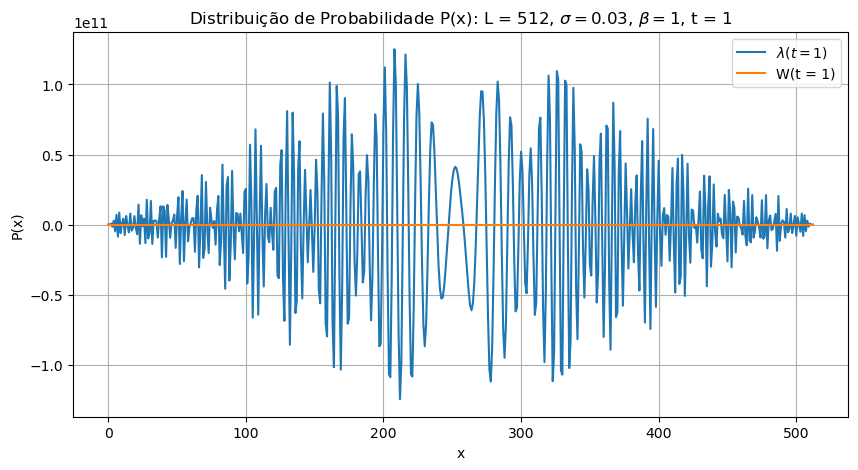

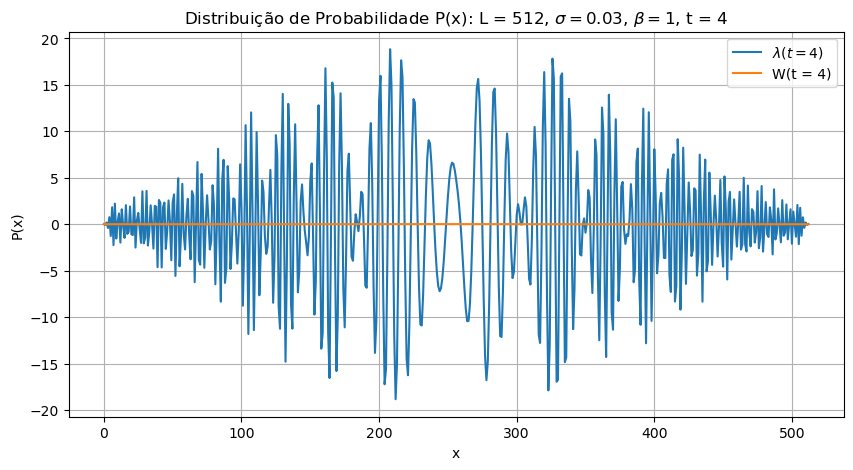

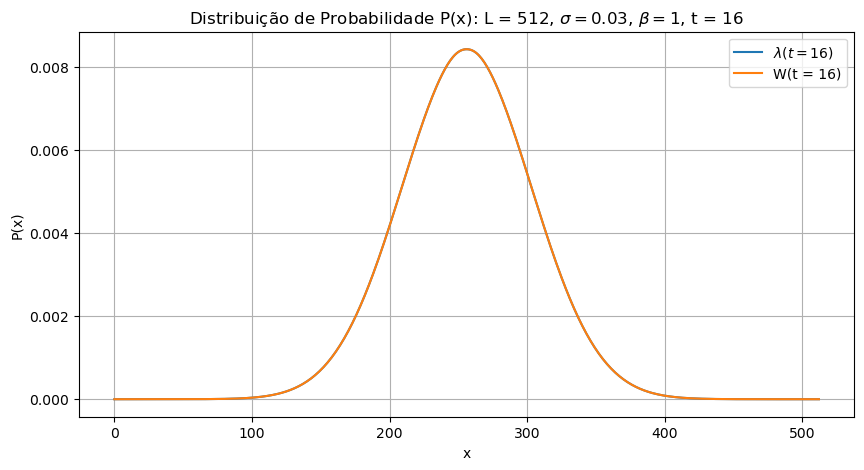

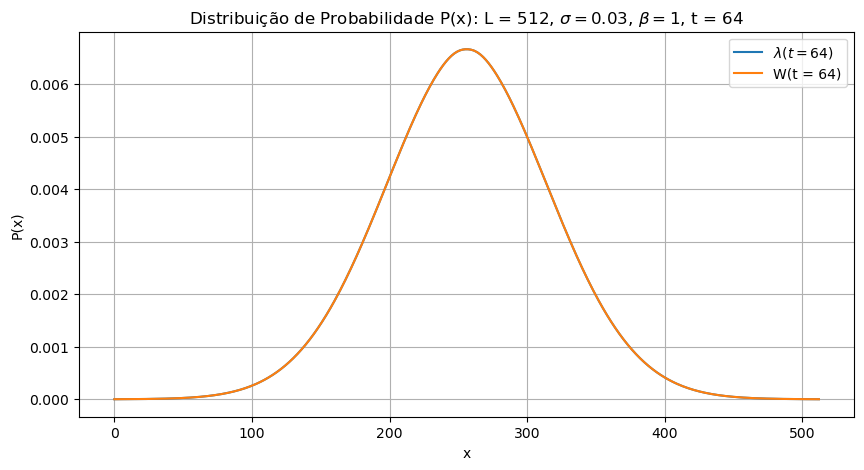

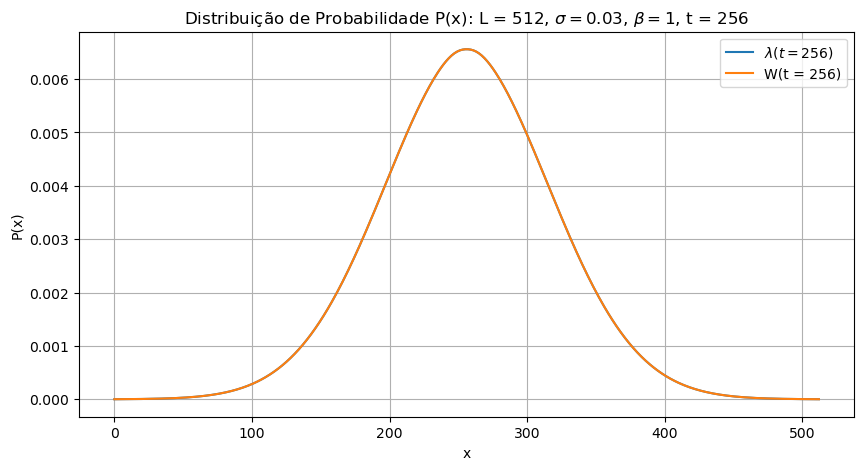

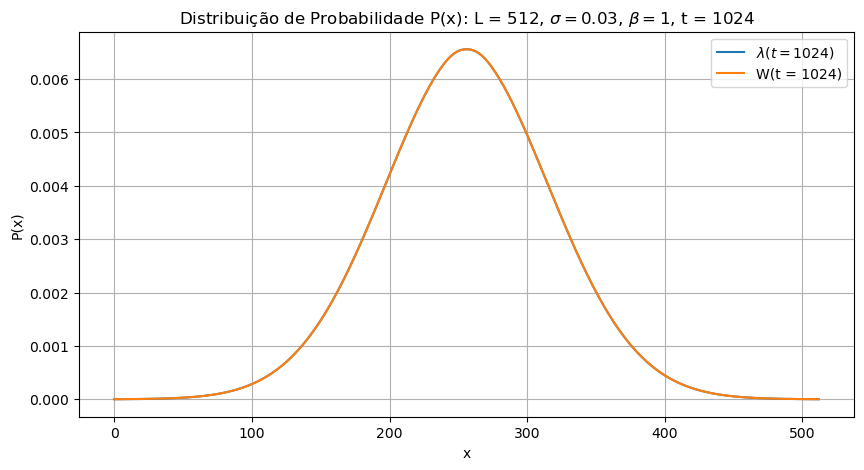

In [ ]:
def Eig_Evolution(L, sigma, beta, t):
    R_M, L_M = Diag(L, sigma, beta)
    P_i = np.zeros(L+1)
    P_i[L // 2] = 1
    P_t = np.zeros(L+1)
    
    x = np.arange(0, L+1, 1)
    coeff = np.zeros(L+1)
    
    for j in range(len(coeff)):
        coeff[j] = np.dot(L_M[:,j], P_i)
        P_t += coeff[j] * np.abs(eigvals[j])**t * R_M[:,j]
    return P_t

x = np.arange(0, 513, 1)
t = np.array([1, 4, 16, 64, 256, 1024])

for T in t:
    P_eig = Eig_Evolution(L = 512, sigma = 0.03, beta = 1, t = T)
    P_M = Markov_Evolution(L = 512, sigma = 0.03, beta = 1, t = T)
    plt.figure(figsize = (10,5))
    plt.title(r"Distribuição de Probabilidade P(x): L = 512, $\sigma = 0.03$, $\beta = 1$, t = {0}" .format(T))
    plt.xlabel("x")
    plt.ylabel("P(x)")
    plt.grid(visible = True)
    plt.plot(x, P_eig, label = r"$\lambda (t = {0})$" .format(T))
    plt.plot(x, P_M, label = r"W(t = {0})" .format(T))
    plt.legend()
    plt.show()

### 1.5 Equilibration time

Podemos calcular o tempo $\tau$ de equilibração introduzindo uma certa tolerância, $\epsilon$, tal que:
$$P_i (t+1) - P_i (t) < \epsilon, \forall i$$
então podemos afirmar que $\tau = t$ é o tempo de equilibração da distribuição de probabilidade estudada. Expressando estas probabilidades e a sua evolução temporal em relação aos valores próprios $\lambda$:
$$P_i(t+1) - P_i(t) = \sum_{\alpha} a_{\alpha} (\lambda_{\alpha}^{t+1} - \lambda_{\alpha}^{t}) r_i^{(\alpha)} < \epsilon, \forall i$$

In [ ]:
def Equilibrium(L, sigma, beta, T, epsilon):
    P_i = np.zeros(L+1)
    P_i[L // 2] = 1
    for t in T:
        P_t = Eig_Evolution(L, sigma, beta, t)
        if (np.all(np.abs(P_t - P_i < epsilon))):
            return t
        else:
            P_i = P_t

time = np.arange(16, 64, 1)
t = Equilibrium(L = 512, sigma = 0.03, beta = 1, T = time, epsilon = 10**-5)
print("O tempo de equilibrio é t = {0}" .format(t))

O tempo de equilibrio é t = 41


### 1.6 Equilibration time as a function of σ and β

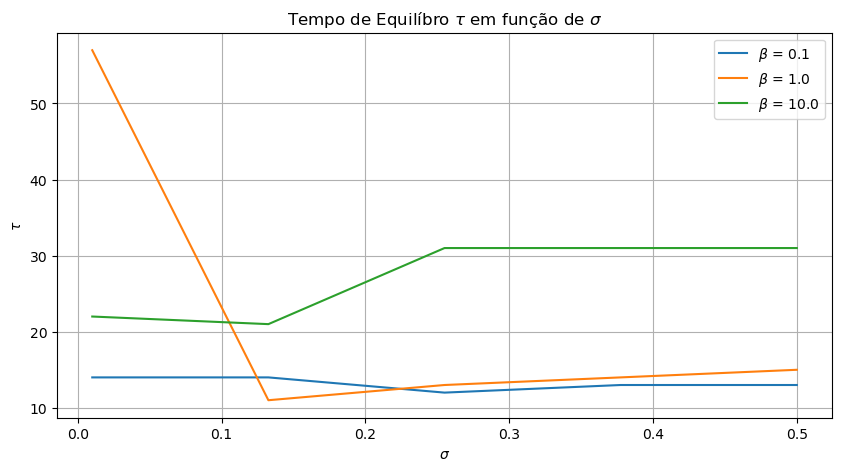

In [ ]:
Sigmas = np.linspace(0.01, 0.5, 5)
Betas = np.array([0.1, 1, 10])
time = np.arange(10, 200, 1)
Tau = np.zeros(len(Sigmas))

for Beta in Betas:
    for i in range(len(Sigmas)):
        Tau[i] = Equilibrium(L = 512, sigma = Sigmas[i], beta = Beta, T = time, epsilon = 10**-4)
    plt.figure(figsize = (10,5), num = 1)
    plt.title(r"Tempo de Equilíbro $\tau$ em função de $\sigma$")
    plt.xlabel(r"$\sigma$")
    plt.ylabel(r"$\tau$")
    plt.grid(visible = True)
    plt.plot(Sigmas, Tau, label = r"$\beta$ = {0}" .format(Beta))
    plt.legend()

### 1.7 Illustrating the dynamics

É possível verificar que o tempo de equilíbrio é inversamente proporcional a $\beta$, ou seja, sendo $\beta$ o inverso da temperatura, pode-se afirmar que uma partícula com maior temperatura irá ter uma maior propensão a ocupar outros estados excitados e será então mais demorado até termos uma distribuição de probabilidade estacionária. O aumento do valor de $\sigma$ confere uma maior difusão no movimento da partícula, ou seja, mais rapidamente irá ocupar posições com uma probabilidade estacionária.

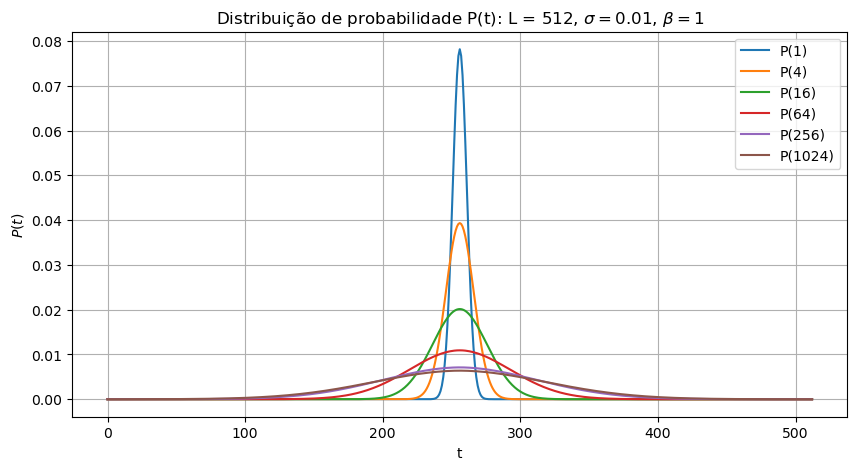

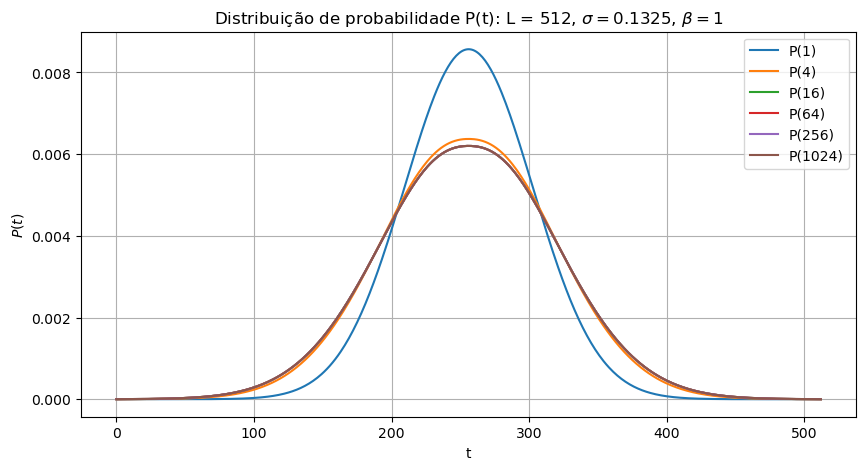

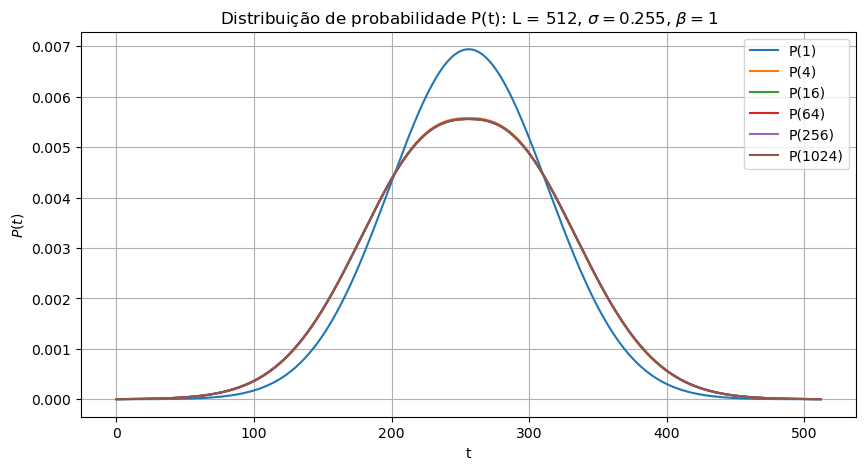

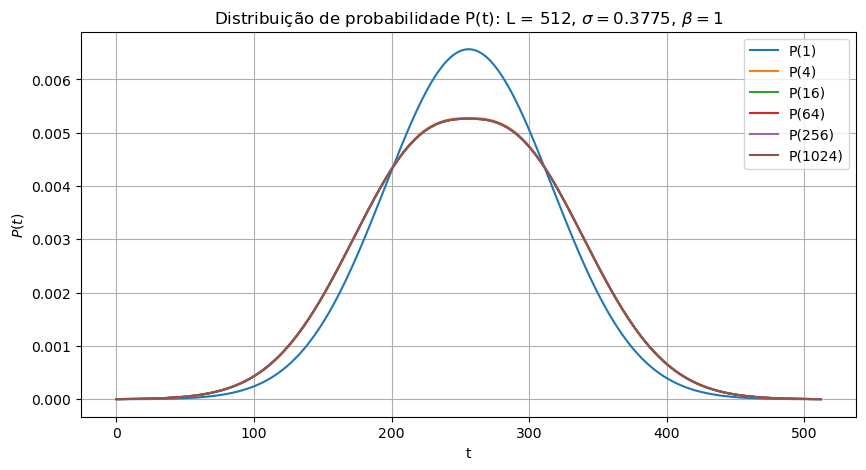

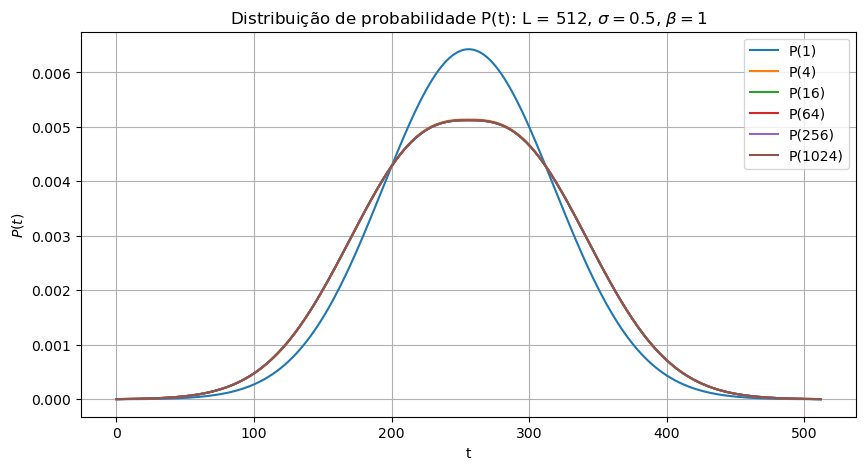

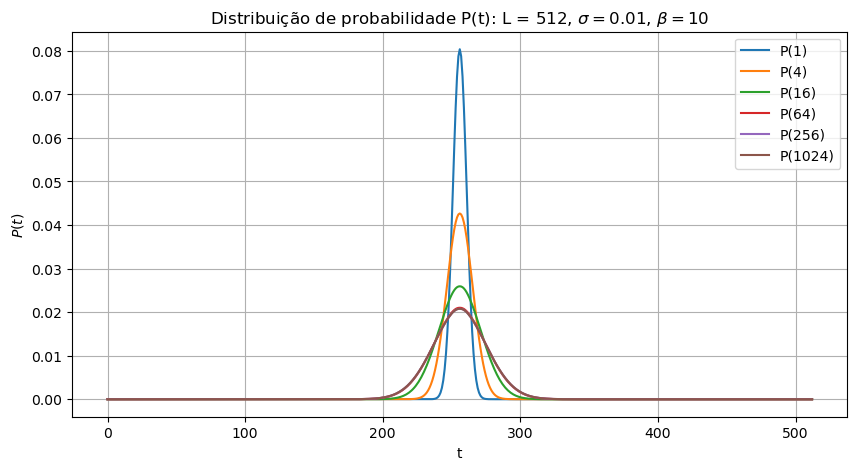

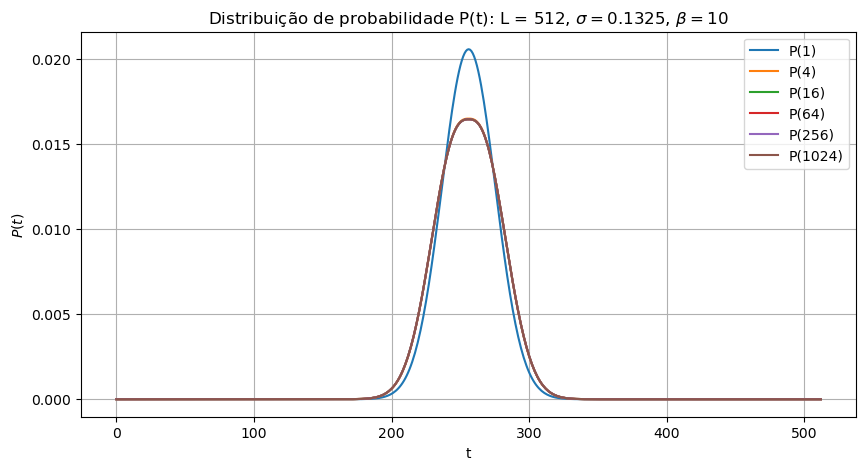

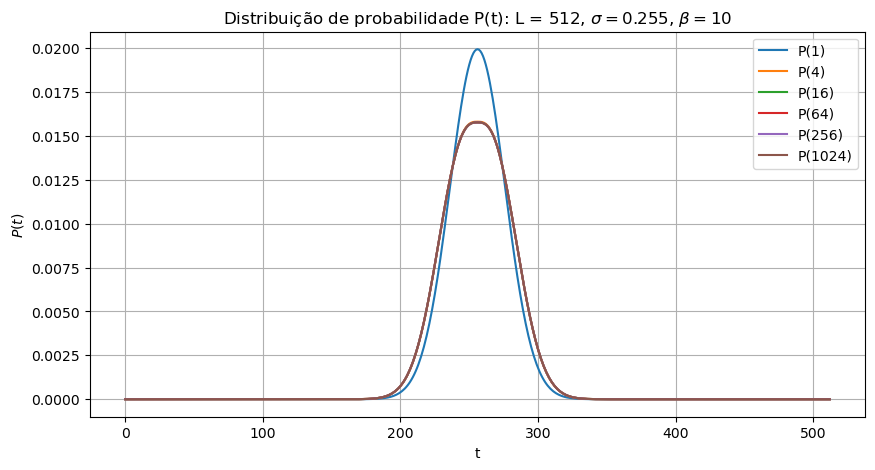

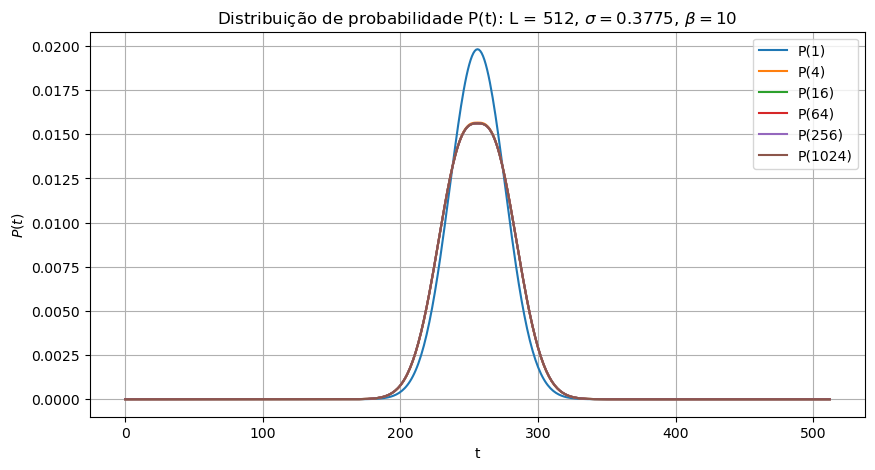

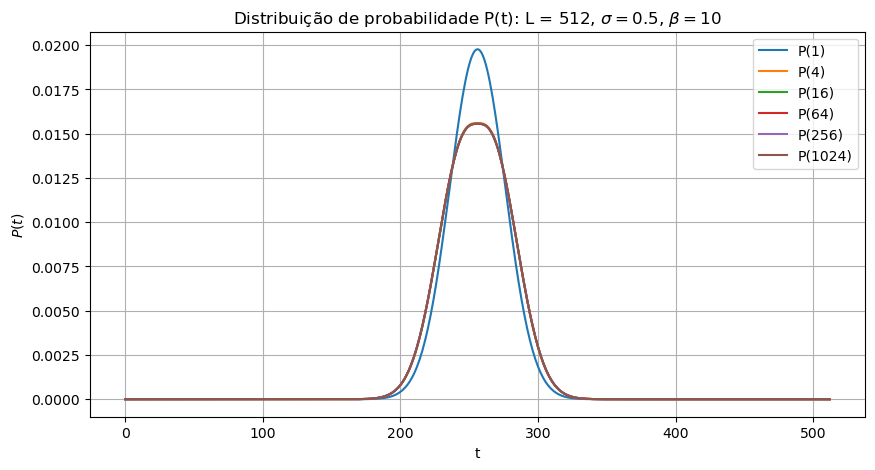

In [ ]:
Sigmas = np.linspace(0.01, 0.5, 5)
Betas = np.array([1, 10])
t = np.array([1, 4, 16, 64, 256, 1024])
fig_number = 1

for Beta in Betas:
    for Sigma in Sigmas:
        for T in t:
            plt.figure(figsize = (10,5), num = fig_number)
            plt.title(r'Distribuição de probabilidade P(t): L = 512, $\sigma = {0}$, $\beta = {1}$' .format(Sigma, Beta))
            plt.xlabel('t')
            plt.ylabel('$P(t)$')
            plt.grid(visible = True)
            plt.plot(np.arange(0,513,1), Markov_Evolution(L = 512, sigma = Sigma, beta = Beta, t = T), label = "P({0})" .format(T))
            plt.legend()
        plt.show()
        fig_number += 1
    fig_number += 1

## 2. Harmonic potential with a central barrier
### 2.1 Transition matrix and time evolution

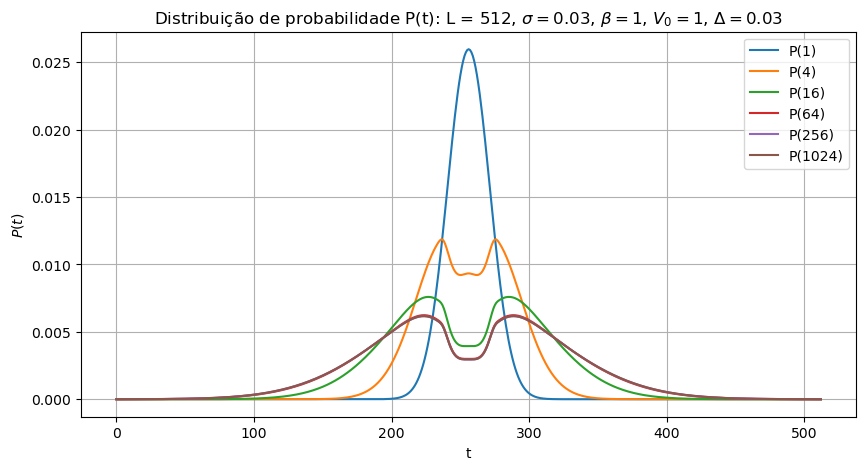

In [ ]:
def Markov_Mod(L, sigma, beta, V_0, delta):
    W = np.zeros((L+1, L+1))
    for i in range(L+1):
        for j in range(L+1):
            E_ij = np.exp(-(i - j)**2 / (2 * sigma**2 * L**2))
            V_i = 32 * (i/L - 0.5)**2 + V_0 * np.exp(-(i/L - 0.5)**4 / delta**4)
            V_j = 32 * (j/L - 0.5)**2 + V_0 * np.exp(-(j/L - 0.5)**4 / delta**4)
            A_ij = min(1, np.exp(beta * (V_j - V_i)))
            W[i,j] = A_ij * E_ij
    W /= W.sum(axis = 0)
    return W

def Markov_Evolution_Mod(L, sigma, beta, V_0, delta, t):
    P_0 = np.zeros(L+1)
    P_0[L//2] = 1
    W = Markov_Mod(L, sigma, beta, V_0, delta)
    W_t = np.linalg.matrix_power(W, t)
    P_f = np.dot(W_t, P_0)
    return P_f

t = np.array([1, 4, 16, 64, 256, 1024])

for T in t:
    plt.figure(figsize = (10,5), num = 1)
    plt.title(r'Distribuição de probabilidade P(t): L = 512, $\sigma = 0.03$, $\beta = 1$, $V_0 = 1$, $\Delta = 0.03$')
    plt.xlabel('t')
    plt.ylabel('$P(t)$')
    plt.grid(visible = True)
    plt.plot(np.arange(0,513,1), Markov_Evolution_Mod(L = 512, sigma = 0.03, V_0 = 1, delta = 0.03, beta = 1, t = T), label = "P({0})" .format(T))
    plt.legend()

#### Δ = 0.03, V₀ = 2

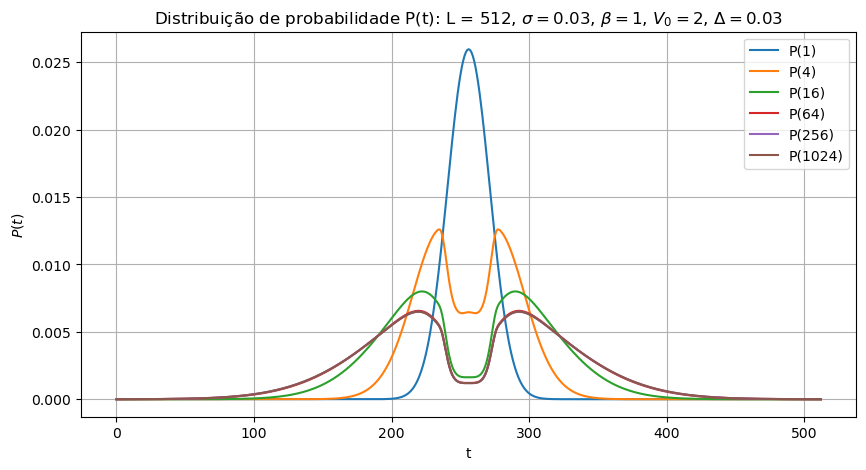

In [ ]:
for T in t:
    plt.figure(figsize = (10,5), num = 1)
    plt.title(r'Distribuição de probabilidade P(t): L = 512, $\sigma = 0.03$, $\beta = 1$, $V_0 = 2$, $\Delta = 0.03$')
    plt.xlabel('t')
    plt.ylabel('$P(t)$')
    plt.grid(visible = True)
    plt.plot(np.arange(0,513,1), Markov_Evolution_Mod(L = 512, sigma = 0.03, V_0 = 2, delta = 0.03, beta = 1, t = T), label = "P({0})" .format(T))
    plt.legend()

#### Δ = 0.03, V₀ = 4

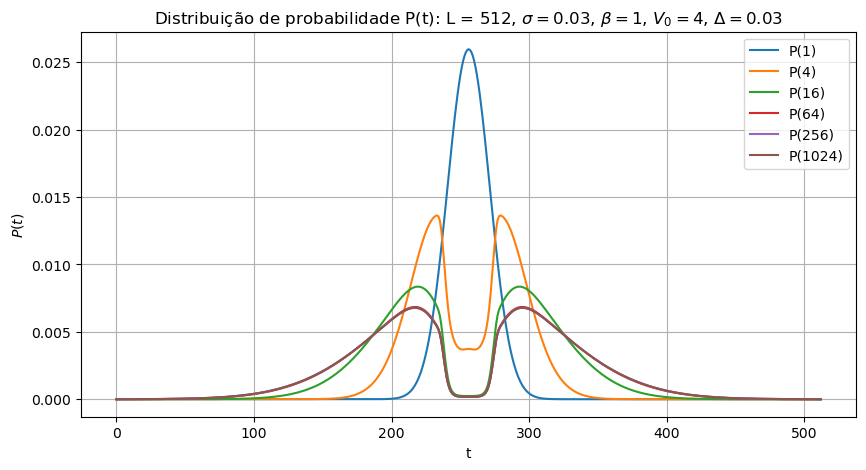

In [ ]:
for T in t:
    plt.figure(figsize = (10,5), num = 1)
    plt.title(r'Distribuição de probabilidade P(t): L = 512, $\sigma = 0.03$, $\beta = 1$, $V_0 = 4$, $\Delta = 0.03$')
    plt.xlabel('t')
    plt.ylabel('$P(t)$')
    plt.grid(visible = True)
    plt.plot(np.arange(0,513,1), Markov_Evolution_Mod(L = 512, sigma = 0.03, V_0 = 4, delta = 0.03, beta = 1, t = T), label = "P({0})" .format(T))
    plt.legend()

#### Δ = 0.03, V₀ = 16

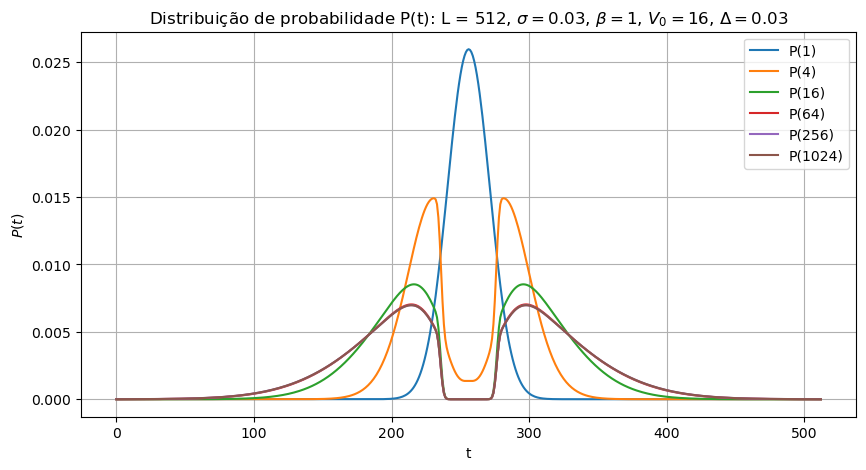

In [ ]:
for T in t:
    plt.figure(figsize = (10,5), num = 1)
    plt.title(r'Distribuição de probabilidade P(t): L = 512, $\sigma = 0.03$, $\beta = 1$, $V_0 = 16$, $\Delta = 0.03$')
    plt.xlabel('t')
    plt.ylabel('$P(t)$')
    plt.grid(visible = True)
    plt.plot(np.arange(0,513,1), Markov_Evolution_Mod(L = 512, sigma = 0.03, V_0 = 16, delta = 0.03, beta = 1, t = T), label = "P({0})" .format(T))
    plt.legend()

### 2.2 Larger hop size, σ = 0.1

Se $\sigma = 1$, existe um aumento da difusão da partícula, ou seja, existe logo uma maior probabilidade de fugir da barreira de potencial central aonde é colocada no início e então ocupar posições que estão de acordo com a probabilidade estacionária. Como temos $\bf{F} = -\nabla V$, é possível também deduzir que quanto maior for o valor de $V_0$, ou seja, o valor de potencial da barreira central, menos provável é a partícula ocupar posições junto a essa barreira numa configuração estacionária.

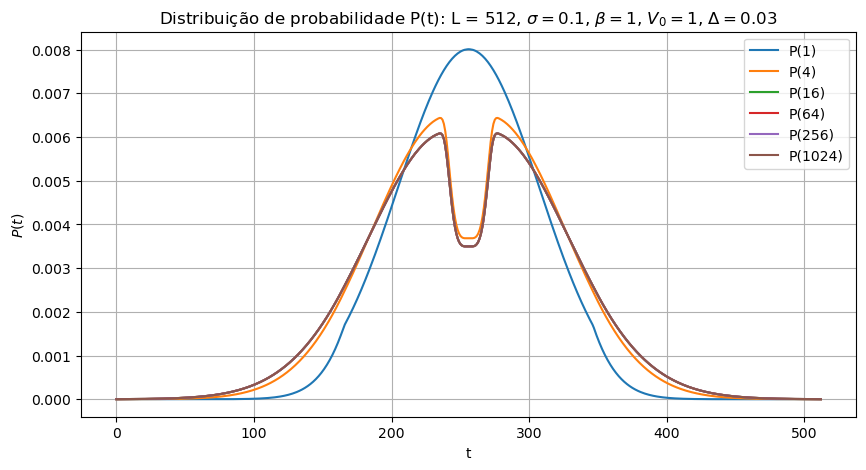

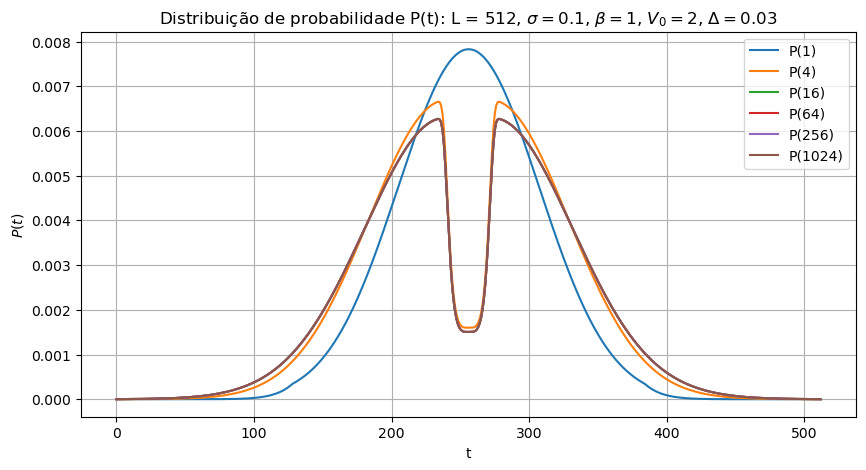

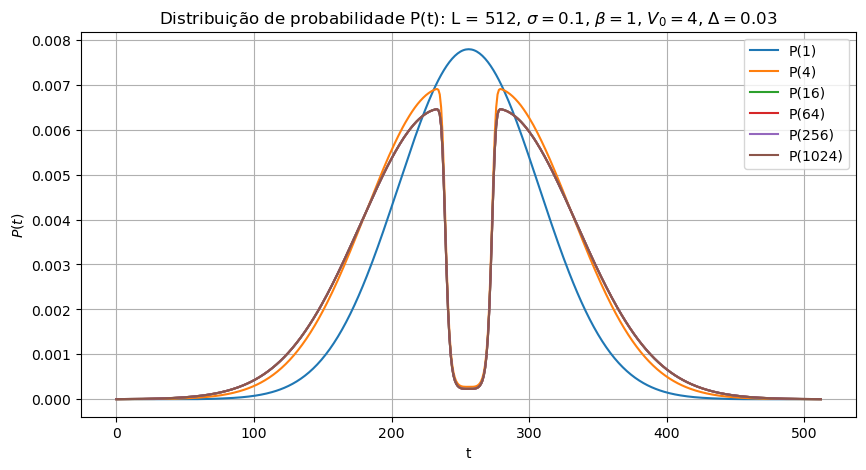

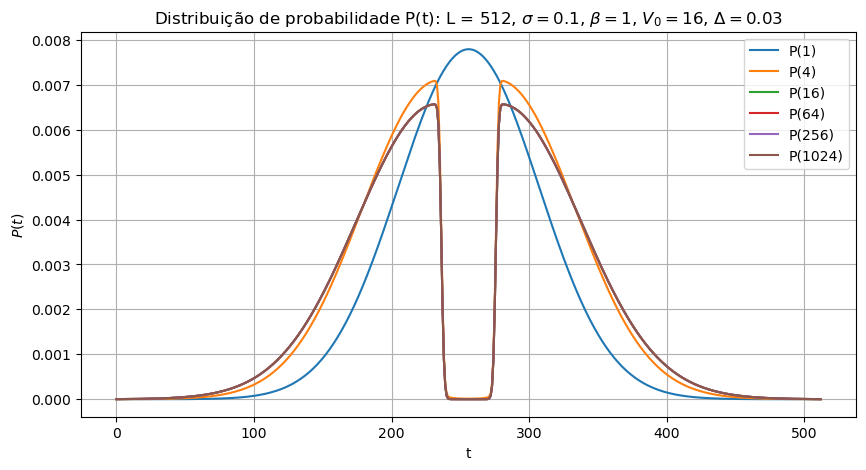

In [ ]:
V_0 = np.array([1, 2, 4, 16])
fig_number = 1

for V in V_0:
    for T in t:
        plt.figure(figsize = (10,5), num = fig_number)
        plt.title(r'Distribuição de probabilidade P(t): L = 512, $\sigma = 0.1$, $\beta = 1$, $V_0 = {0}$, $\Delta = 0.03$' .format(V))
        plt.xlabel('t')
        plt.ylabel('$P(t)$')
        plt.grid(visible = True)
        plt.plot(np.arange(0,513,1), Markov_Evolution_Mod(L = 512, sigma = 0.1, V_0 = V, delta = 0.03, beta = 1, t = T), label = "P({0})" .format(T))
        plt.legend()
    plt.show()
    fig_number += 1

### 2.3 Equilibration times with the barrier

Para um valor $\sigma = 0.03$, o tempo de equilíbrio irá ser relativamente igual independentemente da magnitude da barreira de potencial central, enquanto que para $\sigma = 0.1$, o tempo de equilíbrio é tão menor quanto for a barreira de potencial central. Isto faz sentido pois com uma probabilidade maior de a partícula poder transitar para os estados à sua beira, ou seja, para $\sigma = 0.1$, se a barreira de potencial central for de menor magnitude, facilmente a partícula pode ficar mais perto desta barreira em relação a valores de $V_0$ mais elevados e ocupar um estado estacionário.

In [ ]:
def Diag_Mod(L, sigma, beta, V_0, delta):
    W = Markov_Mod(L, sigma, beta, V_0, delta)

    # O SciPy oferce vetores com norma = 1
    eigvals, R_V = sci.linalg.eig(W)
    L_V = sci.linalg.eig(W.T)[1]

    # Matrizes
    R_M = np.zeros((513, 513))
    L_M = np.zeros((513, 513))

    for k in range(W.shape[1]):
        if np.isclose(eigvals[k], 1):
            R_M[:,k] = R_V[:,k] / np.sum(R_V[:,k])
            L_M[:,k] = L_V[:,k] / np.sum(L_V[:,k] * R_M[:,k])
        else:
            L_M[:,k] = L_V[:,k] / np.linalg.norm(L_V[:,k])
            R_M[:,k] = R_V[:,k] / np.sum(R_V[:,k] * L_M[:,k])
    return R_M, L_M

def Eig_Evolution_Mod(L, sigma, beta, V_0, delta, t):
    R_M, L_M = Diag_Mod(L, sigma, beta, V_0, delta)
    P_i = np.zeros(L+1)
    P_i[L // 2] = 1
    P_t = np.zeros(L+1)
    
    x = np.arange(0, L+1, 1)
    coeff = np.zeros(L+1)
    
    for j in range(len(coeff)):
        coeff[j] = np.dot(L_M[:,j], P_i)
        P_t += coeff[j] * np.abs(eigvals[j])**t * R_M[:,j]
    return P_t

def Equilibrium_Mod(L, sigma, beta, V_0, delta, T, epsilon):
    P_i = np.zeros(L+1)
    P_i[L // 2] = 1
    for t in T:
        P_t = Eig_Evolution_Mod(L, sigma, beta, V_0, delta, t)
        if (np.all(np.abs(P_t - P_i < epsilon))):
            return t
        else:
            P_i = P_t

time = np.arange(10, 100, 1)

t_1 = Equilibrium_Mod(L = 512, sigma = 0.03, beta = 1, V_0 = 1, delta = 0.03, T = time, epsilon = 10**-4)
print("O tempo de equilibrio é t = {0} para sigma = 0.03 e V_0 = 1" .format(t_1))

t_2 = Equilibrium_Mod(L = 512, sigma = 0.03, beta = 1, V_0 = 2, delta = 0.03, T = time, epsilon = 10**-4)
print("O tempo de equilibrio é t = {0} para sigma = 0.03 e V_0 = 2" .format(t_2))

t_3 = Equilibrium_Mod(L = 512, sigma = 0.03, beta = 1, V_0 = 4, delta = 0.03, T = time, epsilon = 10**-4)
print("O tempo de equilibrio é t = {0} para sigma = 0.03 e V_0 = 4" .format(t_3))

t_4 = Equilibrium_Mod(L = 512, sigma = 0.03, beta = 1, V_0 = 16, delta = 0.03, T = time, epsilon = 10**-4)
print("O tempo de equilibrio é t = {0} para sigma = 0.03 e V_0 = 16" .format(t_4))

t_5 = Equilibrium_Mod(L = 512, sigma = 0.1, beta = 1, V_0 = 1, delta = 0.03, T = time, epsilon = 10**-4)
print("O tempo de equilibrio é t = {0} para sigma = 0.1 e V_0 = 1" .format(t_5))

t_6 = Equilibrium_Mod(L = 512, sigma = 0.1, beta = 1, V_0 = 2, delta = 0.03, T = time, epsilon = 10**-4)
print("O tempo de equilibrio é t = {0} para sigma = 0.1 e V_0 = 2" .format(t_6))

t_7 = Equilibrium_Mod(L = 512, sigma = 0.1, beta = 1, V_0 = 4, delta = 0.03, T = time, epsilon = 10**-4)
print("O tempo de equilibrio é t = {0} para sigma = 0.1 e V_0 = 4" .format(t_7))

t_8 = Equilibrium_Mod(L = 512, sigma = 0.1, beta = 1, V_0 = 16, delta = 0.03, T = time, epsilon = 10**-4)
print("O tempo de equilibrio é t = {0} para sigma = 0.1 e V_0 = 16" .format(t_8))

O tempo de equilibrio é t = 16 para sigma = 0.03 e V_0 = 1
O tempo de equilibrio é t = 17 para sigma = 0.03 e V_0 = 2
O tempo de equilibrio é t = 17 para sigma = 0.03 e V_0 = 4
O tempo de equilibrio é t = 17 para sigma = 0.03 e V_0 = 16
O tempo de equilibrio é t = 11 para sigma = 0.1 e V_0 = 1
O tempo de equilibrio é t = 12 para sigma = 0.1 e V_0 = 2
